# Exploración inicial: NYC Taxi Trip Duration

Exploración rápida en Python. **No se modifica el dataset**, solo se lee y se describe.
La versión entregable de la exploración inicial se hará en Scala.

**Contenido**
1. Carga de datos
2. Tamaño, tipos y nulos
3. Estadísticas básicas y rango temporal
4. Clase (short / medium / long)
5. Variables categóricas y discretas
6. Duplicados, inconsistencias, outliers y ruido
   - 6.1 Duplicados · 6.2 Duración frente a fechas · 6.3 Outliers de duración
   - 6.4 Pasajeros y coordenadas · 6.4.1 Coordenadas imposibles
   - 6.5 Ruido: distancia (0 km) · 6.6 Resumen y filtro combinado
7. Distribución de los atributos (gráficas)
   - 7.1 Duración, distancia y mapa · 7.2 Coordenadas y pasajeros
8. Correlación de los datos
   - 8.1 Entre atributos · 8.2 Numéricos frente a la clase
   - 8.3 Categóricos frente a la clase · 8.4 Temporales frente a la clase
9. Observaciones para la limpieza

## 1. Carga de datos

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = "train.csv"
df = pd.read_csv(PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 2. Tamaño, tipos y nulos

**Suposición:** 1.458.644 filas y 11 columnas, sin valores ausentes (el conjunto fue
depurado para la competición). Confirmar con la salida.


In [62]:
print("Filas y columnas:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)
print("\nNulos por columna:")
print(df.isnull().sum())

Filas y columnas: (1458644, 11)

Tipos de dato:
id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object

Nulos por columna:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64


**Resultado:** 1.458.644 filas y 11 columnas, sin ausentes en ninguna. `id` y
`store_and_fwd_flag` son texto; `vendor_id`, `passenger_count` y `trip_duration`, enteros;
las 4 coordenadas, decimales; las 2 fechas, datetime.

## 3. Estadísticas básicas y rango temporal

`describe()` solo calcula media, desviación, etc. para las columnas numéricas.
En los atributos no numéricos no se pueden calcular.

**Suposición:** `vendor_id` aparecerá en la tabla porque son enteros, pero es nominal
y su media no tiene sentido. Lo mismo con `passenger_count`, que es discreto.


In [63]:
# Estadísticas de las columnas numéricas
display(df.describe().T)

# Rango temporal real de los viajes (no confundir con las fechas de la competición)
print("Primer viaje:", df["pickup_datetime"].min())
print("Último viaje:", df["pickup_datetime"].max())

,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


Primer viaje: 2016-01-01 00:00:17
Último viaje: 2016-06-30 23:59:39


**Resultado:**
- Viajes iniciados entre 2016-01-01 00:00:17 y 2016-06-30 23:59:39 (`pickup_datetime`); el último `dropoff_datetime` es 2016-07-01 23:02:03.
- `vendor_id` y `passenger_count` salen en la tabla por ser enteros, pero su media no es interpretable (nominal y discreto).
- Coordenadas imposibles para Nueva York: longitud entre −121,93 y −61,34; latitud de recogida entre 34,36 y 51,88 y de destino entre 32,18 y 43,92.
- `trip_duration`: mín 1 s, mediana 662 s, media 959 s, desviación 5.237 s, máx 3.526.282 s (40 días y 19 horas). Media > mediana y desviación mucho mayor que la media: distribución muy sesgada por los extremos.

## 4. Clase: short / medium / long

Se construye a partir de `trip_duration` (segundos):
- **short**: ≤ 10 min
- **medium**: entre 10 y 25 min (el 25 incluido)
- **long**: > 25 min

Es una variable temporal para explorar; el dataset original no se toca.

In [64]:
# Duración en minutos
columna_clase_min = df["trip_duration"] / 60

# np.select equivale a un if / elif / else vectorizado:
# toma la primera condición que se cumple; si ninguna, usa default
columna_clase_transformada = np.select(
    [columna_clase_min <= 10, columna_clase_min <= 25],
    ["short", "medium"],
    default="long"
)

# Convertimos el array de NumPy en una Series de pandas para poder usar value_counts()
orden = ["short", "medium", "long"]
cantidad_por_clase = pd.Series(columna_clase_transformada).value_counts().reindex(orden)
porcentaje_por_clase = (cantidad_por_clase / cantidad_por_clase.sum() * 100).round(2)

print("En total hay", len(cantidad_por_clase), "clases\n")
print("Recuento:")
print(cantidad_por_clase)
print("\nPorcentaje (%):")
print(porcentaje_por_clase)

En total hay 3 clases

Recuento:
short     652913
medium    625309
long      180422
Name: count, dtype: int64

Porcentaje (%):
short     44.76
medium    42.87
long      12.37
Name: count, dtype: float64


**Resultado:** short 652.913 (44,76 %), medium 625.309 (42,87 %), long 180.422 (12,37 %).
Moda: short. Ninguna clase domina, pero long es una minoría clara (unas 3,6 veces menos que
short).


## 5. Variables categóricas y discretas

Nominales, booleanos y discretos: a los atributos que no son numéricos continuos no se
les puede calcular una media ni una desviación, así que se describen contando cuántas
veces aparece cada valor.
En este apartado se busca: valores posibles, ausentes, moda (lo más frecuente) y
distribución (frecuencias). Con ello se detectan valores no válidos, atributos
irrelevantes y categorías muy raras.

### 5.1 Identificador, nominal y booleano

**Suposición:** `id` es único (no sirve para predecir); `vendor_id` solo toma los
valores 1 y 2; `store_and_fwd_flag` es casi siempre N.

In [65]:
print("id: valores distintos =", df["id"].nunique(), "de", len(df))
print("id ausentes:", df["id"].isnull().sum())

for col in ["vendor_id", "store_and_fwd_flag"]:
    print(f"\n--- {col} ---")
    print("Valores posibles:", sorted(df[col].dropna().unique()))
    print("Ausentes:", df[col].isnull().sum())   # (ya se revisó que no hubiera)
    print("Moda:", df[col].mode()[0])
    print("Frecuencia (%):")
    print((df[col].value_counts(normalize=True) * 100).round(2))

id: valores distintos = 1458644 de 1458644
id ausentes: 0

--- vendor_id ---
Valores posibles: [np.int64(1), np.int64(2)]
Ausentes: 0
Moda: 2
Frecuencia (%):
vendor_id
2    53.5
1    46.5
Name: proportion, dtype: float64

--- store_and_fwd_flag ---
Valores posibles: ['N', 'Y']
Ausentes: 0
Moda: N
Frecuencia (%):
store_and_fwd_flag
N    99.45
Y     0.55
Name: proportion, dtype: float64


**Resultado:**
- `id`: único (1.458.644 distintos en 1.458.644 filas), sin valor predictivo.
- `vendor_id`: solo toma 1 y 2; moda 2 (53,5 % frente a 46,5 %).
- `store_and_fwd_flag`: solo toma N e Y; moda N (99,45 %); Y es el 0,55 % (unos 8.000 viajes).


### 5.2 Discreto: `passenger_count`

**Suposición:** la moda es 1 y aparecen valores raros (0 y 7 o más).

In [66]:
print("Valores posibles:", sorted(df["passenger_count"].dropna().unique()))  # nº de pasajeros por vehículo
print("Ausentes:", df["passenger_count"].isnull().sum())
print("Moda:", df["passenger_count"].mode()[0])
print("\nRecuento por valor:")
print(df["passenger_count"].value_counts().sort_index())

Valores posibles: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Ausentes: 0
Moda: 1

Recuento por valor:
passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64


**Resultado:**
- Valores de 0 a 9; moda 1 (1.033.540 viajes, ≈ 70,9 %).
- Sospechosos: 0 pasajeros (60 viajes) y 7, 8 y 9 pasajeros (3, 1 y 1 viajes).
- Entre 1 y 6 el reparto no es monótono (con 5 pasajeros hay más viajes que con 3 o con 4); no sabemos la causa y no hay base para tratarlo como error.


### 5.3 Fechas: ausentes y distribución temporal

**Suposición:** seis meses con un volumen parecido, más viajes de jueves a sábado,
mínimo de madrugada y pico por la tarde.

pickup_datetime -> ausentes: 0
dropoff_datetime -> ausentes: 0

Viajes por mes (pickup):
pickup_datetime
1    229707
2    238300
3    256189
4    251645
5    248487
6    234316
Name: count, dtype: int64
Valores distintos de los atributos temporales
pickup_datetime:  1,380,222
dropoff_datetime: 1,380,377


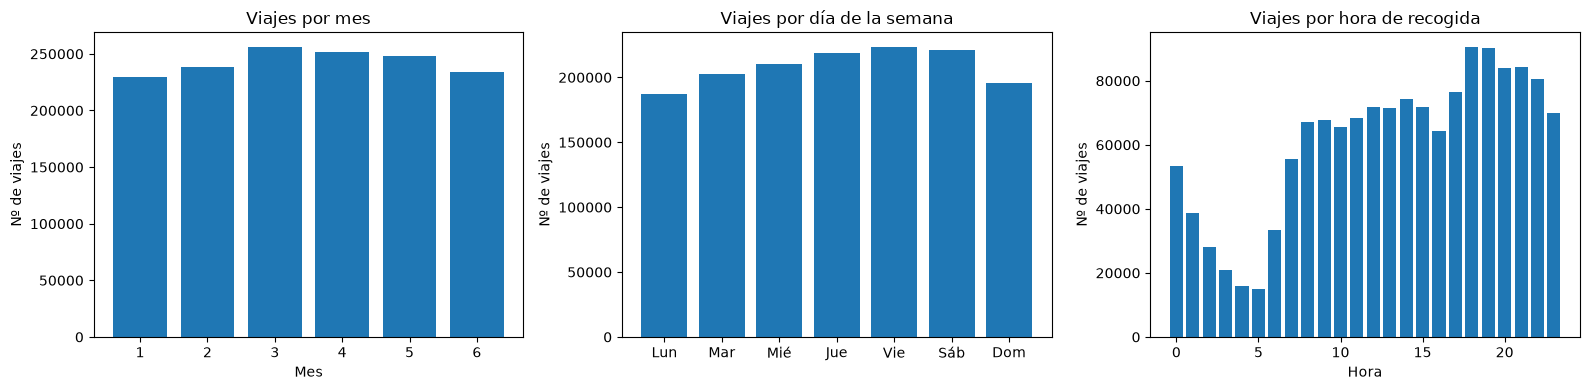

In [67]:
for col in ["pickup_datetime", "dropoff_datetime"]:
    print(f"{col} -> ausentes:", df[col].isnull().sum())

# Pocos valores (6 meses): se dejan también en número para comprobar el rango temporal
print("\nViajes por mes (pickup):")
print(df["pickup_datetime"].dt.month.value_counts().sort_index())
print("Valores distintos de los atributos temporales")
print(f"pickup_datetime:  {df['pickup_datetime'].nunique():,}")
print(f"dropoff_datetime: {df['dropoff_datetime'].nunique():,}")

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_mes = df["pickup_datetime"].dt.month.value_counts().sort_index()
por_dia = df["pickup_datetime"].dt.dayofweek.value_counts().sort_index()
por_hora = df["pickup_datetime"].dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(por_mes.index, por_mes.values)
axes[0].set_title("Viajes por mes")
axes[0].set_xlabel("Mes")

axes[1].bar(dias, por_dia.values)
axes[1].set_title("Viajes por día de la semana")

axes[2].bar(por_hora.index, por_hora.values)
axes[2].set_title("Viajes por hora de recogida")
axes[2].set_xlabel("Hora")

for ax in axes:
    ax.set_ylabel("Nº de viajes")

plt.tight_layout()
plt.savefig("distribucion_temporal.png", dpi=150)
plt.show()


**Resultado:**
- Sin ausentes en las fechas.
- Mes: seis meses con volumen parecido (de 229.707 en enero a 256.189 en marzo).
- Día de la semana: mínimo el lunes (~187.000) y máximo viernes y sábado (~222.000).
- Hora: mínimo hacia las 5 h (~15.000) y máximo a las 18-19 h (~90.000), con un pequeño descenso hacia las 16 h.


## 6. Duplicados, inconsistencias, outliers y ruido

Aquí se detectan los problemas que habrá que tratar en la limpieza. Solo se cuentan;
no se elimina nada. Los valores ausentes ya se revisaron en la sección 2.

### 6.1 Duplicados

Si el número de `id` distintos (sección 5) coincide con el número de filas, no hay
`id` repetidos. Con la comprobación de filas completas se confirma que no hay duplicados.

**Suposición:** 0 en ambos.

In [68]:
print("id duplicados:", df["id"].duplicated().sum())
print("filas completamente duplicadas:", df.duplicated().sum())

id duplicados: 0
filas completamente duplicadas: 0


**Resultado:** 0 `id` duplicados y 0 filas completamente duplicadas.

### 6.2 Inconsistencias entre columnas: duración frente a fechas

La idea es revisar si `trip_duration` es igual a `dropoff_datetime - pickup_datetime`.
Si lo es, `dropoff_datetime` revela la duración y, por tanto, la clase: sería una
**posible fuga de información** y no se podría usar como atributo predictor.

**Suposición:** coinciden en (casi) todas las filas.
Si sale 0 o casi 0, queda confirmado que `dropoff_datetime`
es una fuga de información y habrá que eliminarlo en la selección de atributos.
Además, `dropoff_datetime` no se conoce al empezar el viaje.

In [69]:
(df["trip_duration"] <= 0).sum()  # .sum() cuenta los que son True

# Primero revisar de nuevo el tipo y un ejemplo de la columna trip_duration
print("Trip_duration es de tipo:",df["trip_duration"].dtype)
print("Ejemplo de trip duration:", df["trip_duration"].iloc[0])
dur_calc = (df["dropoff_datetime"] - df["pickup_datetime"]).dt.total_seconds()
print(dur_calc.dtype)
print(df["trip_duration"].iloc[0] != dur_calc.iloc[0])
dur_calc = dur_calc.astype(int)   # trip_duration es entero y total_seconds() devuelve decimal
print("trip_duration distinto de dropoff - pickup:", (dur_calc != df["trip_duration"]).sum())  # posible fuga de información

# Duración calculada con las fechas, en segundos
dur_calc = (df["dropoff_datetime"] - df["pickup_datetime"]).dt.total_seconds().astype(int)

print("trip_duration distinto de dropoff - pickup en segundos:", (dur_calc != df["trip_duration"]).sum())

Trip_duration es de tipo: int64
Ejemplo de trip duration: 455
float64
False
trip_duration distinto de dropoff - pickup: 0
trip_duration distinto de dropoff - pickup en segundos: 0


**Resultado:** `trip_duration` coincide con `dropoff_datetime - pickup_datetime` en las
1.458.644 filas (0 discrepancias). Confirmado: `dropoff_datetime` revela la duración y, por
tanto, la clase. Es una fuga de información y se eliminará en la selección de atributos.

### 6.3 Outliers en la duración

Primero se mira cómo se reparte la duración (boxplot y percentiles) y luego se cuentan los extremos.

El boxplot marca como outliers los puntos fuera de los bigotes (por encima de Q3 + 1,5·IQR o por debajo de Q1 − 1,5·IQR). Con distribuciones tan sesgadas esa regla marca muchísimos puntos, incluidos viajes normales de 40 o 50 min.


C:\Users\diego\AppData\Local\Temp\ipykernel_27872\424602380.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df["trip_duration"], vert=False)
C:\Users\diego\AppData\Local\Temp\ipykernel_27872\424602380.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot((df["trip_duration"] / 60).clip(upper=120), vert=False)


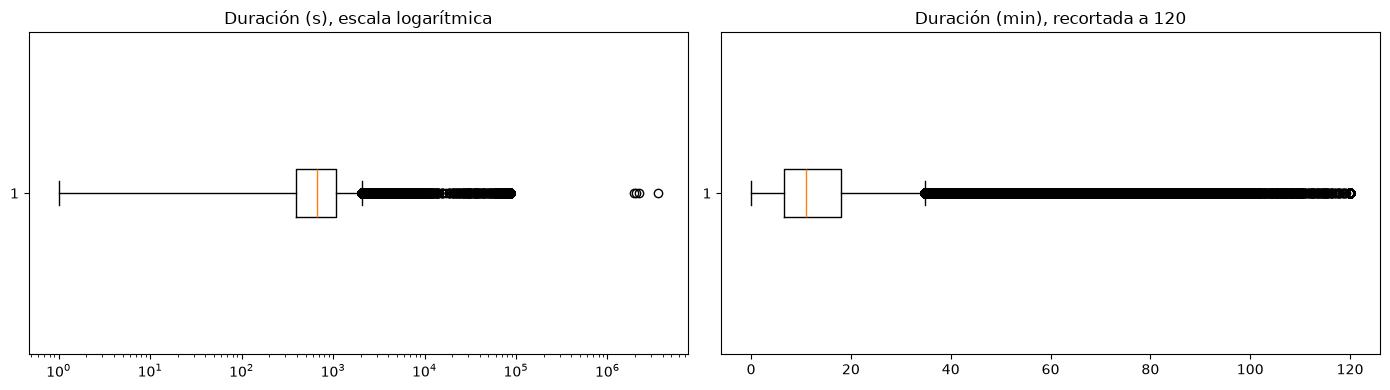

In [70]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Escala logarítmica: se ven todos los datos, incluidos los extremos
axes[0].boxplot(df["trip_duration"], vert=False)
axes[0].set_xscale("log")
axes[0].set_title("Duración (s), escala logarítmica")

# Recortado a 2 h: se ve bien la zona normal
axes[1].boxplot((df["trip_duration"] / 60).clip(upper=120), vert=False)
axes[1].set_title("Duración (min), recortada a 120")

plt.tight_layout()
plt.savefig("boxplot_duracion.png", dpi=150)
plt.show()

**Resultado (boxplot):**
- La zona normal es estrecha: la caja va de unos 400 a 1.100 s (6-18 min) y la mediana ronda los 700 s. La mayoría de los viajes son *short* o *medium*.
- La regla del IQR marca como outlier todo lo que pasa de unos 2.000 s (≈ 35 min).
- La "mancha negra" no se puede contar (cientos de miles de puntos pegados): hay que mirar números.
- Hay tres puntos aislados muy lejos (entre 23 y 40 días): errores claros.
- También hay una acumulación cerca de 10⁵ s (casi 24 h), que no es creíble.


**Cuántos viajes hay por encima y por debajo de cada corte.**
Los umbrales de limpieza se eligen mirando estos números, no la regla del IQR
(que eliminaría viajes *long* legítimos, de más de 25 min).


In [71]:

# Percentiles de la duración (en segundos)
print(df["trip_duration"].quantile([0.001, 0.01, 0.5, 0.99, 0.999]))
print("Mediana", df["trip_duration"].median(),
      "coincide con el cuartil 0.5: el 50% de los datos son menores que este valor y el 50% restante mayores")
print("Máximo duración de un viaje:", df["trip_duration"].max())

0.001        7.000
0.010       87.000
0.500      662.000
0.990     3440.000
0.999    85128.357
Name: trip_duration, dtype: float64
Mediana 662.0 coincide con el cuartil 0.5: el 50% de los datos son menores que este valor y el 50% restante mayores
Máximo duración de un viaje: 3526282


**Resultado (percentiles):** 0,1 % = 7 s; 1 % = 87 s; mediana = 662 s (≈ 11 min);
99 % = 3440 s (≈ 57 min); 99,9 % = 85128 s (≈ 23,6 h). Máximo = 3 526 282 s (≈ 40,8 días).


In [72]:
total = len(df)

print("Viajes largos:")
for horas in [1, 2, 3, 6, 12, 20, 23, 24]:
    n = (df["trip_duration"] > horas * 3600).sum()
    print(f"  duración > {horas} h: {n} ({n / total * 100:.3f} %)")

print("\nViajes muy cortos:")
for seg in [10, 30, 60, 120]:
    n = (df["trip_duration"] < seg).sum()
    print(f"  duración < {seg} s: {n} ({n / total * 100:.3f} %)")

print("\nViajes muy cortos (en minutos):")
# Definimos los cortes en minutos: 0.5 min (30s), 1 min (60s), 2 min (120s), 5 min (300s)
for minutos in [6, 11, 18]: #mas o menos rango de la boxplot
    segundos = minutos * 60
    n = (df["trip_duration"] < segundos).sum()
    print(f"  duración < {minutos} min: {n} ({n / total * 100:.3f} %)")

print("\nduración <= 0 s:", (df["trip_duration"] <= 0).sum())

Viajes largos:
  duración > 1 h: 12317 (0.844 %)
  duración > 2 h: 2253 (0.154 %)
  duración > 3 h: 2112 (0.145 %)
  duración > 6 h: 2061 (0.141 %)
  duración > 12 h: 1993 (0.137 %)
  duración > 20 h: 1933 (0.133 %)
  duración > 23 h: 1843 (0.126 %)
  duración > 24 h: 4 (0.000 %)

Viajes muy cortos:
  duración < 10 s: 1984 (0.136 %)
  duración < 30 s: 4782 (0.328 %)
  duración < 60 s: 8595 (0.589 %)
  duración < 120 s: 27817 (1.907 %)

Viajes muy cortos (en minutos):
  duración < 6 min: 308486 (21.149 %)
  duración < 11 min: 725783 (49.757 %)
  duración < 18 min: 1096531 (75.175 %)

duración <= 0 s: 0


**Resultado:**
- Entre 1 y 2 h hay unos 10.000 viajes (cola normal); a partir de 2 h casi desaparecen.
- Hay un bloque de ≈ 1.840 viajes entre 23 y 24 h. Hipótesis: registros fallidos (por ejemplo, un taxímetro que no se apagó).
- Más de 3 h: 2.112 viajes (0,145 %). Más de 24 h: solo 4, así que un corte de 24 h no los detectaría.
- Menos de 60 s: 8.595 viajes (0,589 %). No hay un salto claro en la distribución.
- Duración <= 0 s: 0 viajes.

**Decisión:** eliminar los viajes de más de 3 h (el corte separa el bloque anómalo de la cola normal, con solo ≈ 141 viajes entre 2 y 3 h) y los de menos de 60 s (un viaje real de menos de 1 min es implausible).


### 6.4 Outliers en pasajeros y coordenadas

Un taxi lleva entre 1 y 6 pasajeros y los viajes deberían estar en la zona de Nueva York.
Los límites usados son el rectángulo aproximado de la ciudad.

**Suposición:** habrá un número pequeño de viajes con 0 pasajeros o con 7 o más, y
algunas coordenadas fuera de la ciudad.

In [73]:
print("passenger_count == 0:", (df["passenger_count"] == 0).sum())
print("passenger_count > 6:", (df["passenger_count"] > 6).sum())

LAT_MIN, LAT_MAX = 40.477, 40.917 #lat y long de New York
LON_MIN, LON_MAX = -74.256, -73.7


recogida_fuera = (~df["pickup_latitude"].between(LAT_MIN, LAT_MAX)
                  | ~df["pickup_longitude"].between(LON_MIN, LON_MAX))
destino_fuera = (~df["dropoff_latitude"].between(LAT_MIN, LAT_MAX)
                 | ~df["dropoff_longitude"].between(LON_MIN, LON_MAX))

print("Recogidas fuera de NYC:", recogida_fuera.sum())
print("Destinos fuera de NYC:", destino_fuera.sum())

passenger_count == 0: 60
passenger_count > 6: 5
Recogidas fuera de NYC: 305
Destinos fuera de NYC: 1329


**Resultado:**
- `passenger_count` == 0: 60 viajes; > 6: 5 viajes.
- Fuera del rectángulo ajustado de Nueva York: 305 recogidas (0,021 %) y 1.329 destinos (0,091 %). Un destino fuera de la ciudad puede ser un viaje real largo; su clase se revisa en 6.5.


### 6.4.1 Coordenadas físicamente imposibles

Los rectángulos de NYC de arriba son solo una referencia: salir de ellos **no** es motivo para eliminar un viaje, porque la recogida o el destino pueden ser puntos reales.
Para decidir qué eliminar se usa un **rectángulo amplio** (lat 40,0–41,5; lon −74,8 a −73,0). Un punto fuera de él queda a cientos de kilómetros de la ciudad (en los datos llega a lon −121,9 y lat 51,9), así que un taxi de NYC no puede estar ahí. Los límites son una elección propia.

Se aplica **el mismo criterio a la recogida y al destino**, porque ambas son coordenadas del mismo viaje. Solo se cuentan; no se elimina nada. Además se mira la clase de esos viajes para ver si pertenecen a alguna en concreto.

In [74]:
# Rectángulo amplio alrededor de NYC 
LAT_AMPLIA = (40.0, 41.5)
LON_AMPLIA = (-74.8, -73.0)

# True si la coordenada cae FUERA del rectángulo amplio
# (~ niega el between, | significa "o": basta con que falle la latitud o la longitud)
recogida_imposible = (
    ~df["pickup_latitude"].between(*LAT_AMPLIA)
    | ~df["pickup_longitude"].between(*LON_AMPLIA)
)
destino_imposible = (
    ~df["dropoff_latitude"].between(*LAT_AMPLIA)
    | ~df["dropoff_longitude"].between(*LON_AMPLIA)
)

print("Recogidas imposibles:", recogida_imposible.sum())
print("Destinos imposibles:", destino_imposible.sum())

print("\nClase de las recogidas imposibles:")
print(pd.Series(columna_clase_transformada[recogida_imposible.values]).value_counts())

print("\nClase de los destinos imposibles:")
print(pd.Series(columna_clase_transformada[destino_imposible.values]).value_counts())

# Viajes con al menos un punto imposible (los que se eliminarán)
alguno_imposible = recogida_imposible | destino_imposible
print("\nViajes con recogida o destino imposible:", alguno_imposible.sum())

Recogidas imposibles: 35
Destinos imposibles: 46

Clase de las recogidas imposibles:
short     20
medium    13
long       2
Name: count, dtype: int64

Clase de los destinos imposibles:
short     23
medium    15
long       8
Name: count, dtype: int64

Viajes con recogida o destino imposible: 49


**Resultado:**
- Con el rectángulo amplio, 35 recogidas y 46 destinos quedan fuera (81 viajes en total, sin solape).
- Los destinos imposibles son 23 short, 15 medium y 8 long: no pertenecen a una clase concreta.

**Decisión:** se eliminan esos 81 viajes, con el mismo criterio para recogida y destino. Los 305 puntos de recogida y los 1.329 destinos que solo salen del rectángulo ajustado de la ciudad **se mantienen**: 901 de esos destinos son `long` y pueden ser viajes reales.


### 6.5 Ruido: distancia

Conociendo la latitud y la longitud de donde se recoge y donde termina el viaje se puede
calcular la distancia recorrida en línea recta (fórmula de haversine). La distancia es un atributo derivado; no se añade a df en esta exploración.

Un viaje de 0 km puede ser legítimo si es muy corto (el cliente cambió de idea, el taxi
no llegó a moverse), pero uno de 0 km que dura mucho tiempo es sospechoso.


In [75]:
#sabiendo latitud y longitud de doden se recogen y donde termina se puede ver la distancia recorrda

def haversine_km(lat1, lon1, lat2, lon2):
    # 1. Pasar de grados a radianes (las funciones seno y coseno de NumPy los piden)
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # 2. Fórmula de haversine: mide lo "separados" que están los dos puntos
    #    sobre una esfera, a partir de la diferencia de latitud y de longitud
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)

    # 3. Convertir ese valor en kilómetros: 6371 es el radio de la Tierra en km
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Usarla: le pasas origen y destino de todos los viajes y devuelve los km de cada uno
distancia_km = haversine_km(df["pickup_latitude"], df["pickup_longitude"],
                            df["dropoff_latitude"], df["dropoff_longitude"])
distancia_km.iloc[100:105]

100     2.782684
101     0.921061
102    19.860051
103     3.015910
104    19.590082
dtype: float64

In [76]:
coordenadas_identicas = (df["pickup_latitude"] == df["dropoff_latitude"]) & (df["pickup_longitude"] == df["dropoff_longitude"])
total_identicos = coordenadas_identicas.sum()
#Obtener los índices en una lista (por si quieres iterar o guardarlos)
indices_identicos = df[coordenadas_identicas].index.tolist()
total = len(df)
print("Análisis previo de coordenadas:")
print(f"  Viajes con coordenadas EXACTAMENTE iguales: {total_identicos} ({total_identicos / total * 100:.3f} %)")
print("Primeros 10 índices con coordenadas idénticas:", indices_identicos[:10])

Análisis previo de coordenadas:
  Viajes con coordenadas EXACTAMENTE iguales: 5897 (0.404 %)
Primeros 10 índices con coordenadas idénticas: [246, 291, 407, 702, 1620, 1728, 1769, 2087, 2441, 2609]


In [77]:
# Viajes de 0 km según lo que duran (el texto sale del propio corte, no puede desajustarse)
print("distancia == 0 km:", (distancia_km == 0).sum())
for segundos in [60, 120, 300, 1500]:
    n = ((distancia_km == 0) & (df["trip_duration"] > segundos)).sum()
    print(f"distancia == 0 km y duración > {segundos} s ({segundos / 60:.0f} min): {n}")

indices_distancias0 = df[distancia_km == 0].index.tolist()
print("Diez primeros Indices distancias 0:", indices_distancias0[:10])
son_identicos = set(indices_identicos) == set(indices_distancias0)

print(f"¿Los índices de distancia 0 y de coordenadas iguales son exactamente los mismos?: {son_identicos}")
# OBSERVACIÓN ANALÍTICA:
# Se observa una coincidencia directa entre estos índices y los identificados previamente 
# con coordenadas de inicio y fin idénticas. Esto confirma que la distancia calculada es 0 
# debido a la ausencia de desplazamiento geográfico registrado por el GPS.

# ¿QUÉ SE HACE CON ESTOS DATOS? (Estrategia de Limpieza):
# Criterio: 0 km no es ruido por sí mismo (coincide con viajes muy cortos o cancelados).
# Se considera sospechoso solo si además dura más de 5 min, porque contradice
# la variable más predictiva (la distancia). Los 0 km de ≤ 5 min se mantienen.


distancia == 0 km: 5897
distancia == 0 km y duración > 60 s (1 min): 4210
distancia == 0 km y duración > 120 s (2 min): 3957
distancia == 0 km y duración > 300 s (5 min): 3191
distancia == 0 km y duración > 1500 s (25 min): 309
Diez primeros Indices distancias 0: [246, 291, 407, 702, 1620, 1728, 1769, 2087, 2441, 2609]
¿Los índices de distancia 0 y de coordenadas iguales son exactamente los mismos?: True


In [78]:
# Seleccionar las filas cuya distancia es 0 km y averiguar cuál es su tiempo máximo
filas_0km = df[distancia_km == 0]

print("Duración máxima entre ellos (s):", filas_0km["trip_duration"].max())
print("Duración máxima entre ellos (min):", round(filas_0km["trip_duration"].max() / 60, 1))

# Viajes de menos de 60 s: ¿cuántos tienen además 0 km? (decide si son ruido)
cortos = df["trip_duration"] < 60
print("Viajes < 60 s:", cortos.sum())
print("  de ellos con distancia == 0 km:", (cortos & (distancia_km == 0)).sum())

Duración máxima entre ellos (s): 86352
Duración máxima entre ellos (min): 1439.2
Viajes < 60 s: 8595
  de ellos con distancia == 0 km: 1675


Las distancias de 0 km coinciden exactamente con los viajes cuyo origen y destino son iguales (mismos índices). El máximo dura 23,97 h (1.439 min). Hipótesis: puede ser una ida y vuelta o un taxímetro encendido, pero con estos datos no se puede comprobar.

In [79]:
largos = df["trip_duration"] > 3 * 3600
print("> 3 h:", largos.sum(), "| de ellos con 0 km:", (largos & (distancia_km == 0)).sum())

print("\nClase de los viajes con destino fuera de NYC:")
print(pd.Series(columna_clase_transformada[destino_fuera.values]).value_counts())

velocidad_kmh = (distancia_km / (df["trip_duration"] / 3600)).replace([np.inf, -np.inf], np.nan)
print("\nvelocidad > 100 km/h:", (velocidad_kmh > 100).sum())
print("Destinos fuera de NYC con velocidad > 100:", (destino_fuera & (velocidad_kmh > 100)).sum())

> 3 h: 2112 | de ellos con 0 km: 3

Clase de los viajes con destino fuera de NYC:
long      901
short     263
medium    165
Name: count, dtype: int64

velocidad > 100 km/h: 175
Destinos fuera de NYC con velocidad > 100: 17


**Resultado:**
- De los 2.112 viajes de más de 3 h, solo 3 tienen 0 km: ambos criterios casi no se solapan.
- De los 1.329 destinos fuera del rectángulo ajustado, 901 son long (67,8 %), 263 short y 165 medium. Muchos pueden ser viajes largos reales; los 428 short y medium son más sospechosos, aunque el rectángulo es aproximado.
- Velocidad > 100 km/h: 175 viajes (0,012 %).

**Decisión:**
- Velocidad: **no se usa como criterio**, porque se calcula con `trip_duration`, que define la clase.
- 0 km y duración > 5 min (3.191 viajes): **se eliminan**, porque contradicen la variable más predictiva (la distancia). Los 0 km de ≤ 5 min se mantienen, porque son coherentes con la clase `short`.

### 6.6 Resumen de lo detectado

**Resultado:** sin ausentes, sin duplicados y sin duraciones <= 0 s; `trip_duration` coincide
con `dropoff - pickup` en todas las filas. Los problemas están en los extremos: 8.595 viajes
de menos de 60 s (0,589 %), 2.112 de más de 3 h (0,145 %), 60 con 0 pasajeros y 5 con más de 6,
305 recogidas y 1.329 destinos fuera del rectángulo, y 3.191 viajes de 0 km con más de 5 min
(0,219 %). Un mismo viaje puede aparecer en varias filas, así que **no se pueden sumar**: NTAIE
y NTOE se calcularán con el filtro combinado en la etapa de limpieza.

In [80]:
resumen = {
    "id duplicados": df["id"].duplicated().sum(),
    "filas completamente duplicadas": df.duplicated().sum(),
    "duración != dropoff - pickup": (dur_calc != df["trip_duration"]).sum(),
    "duración <= 0 s": (df["trip_duration"] <= 0).sum(),
    "duración < 60 s": (df["trip_duration"] < 60).sum(),
    "duración > 3 h": (df["trip_duration"] > 3 * 3600).sum(),
    "passenger_count == 0": (df["passenger_count"] == 0).sum(),
    "passenger_count > 6": (df["passenger_count"] > 6).sum(),
    "recogida fuera de NYC": recogida_fuera.sum(),
    "destino fuera de NYC": destino_fuera.sum(),
    "0 km y duración > 5 min": ((distancia_km == 0) & (df["trip_duration"] > 300)).sum(),
}
tabla = pd.Series(resumen, name="nº de filas").to_frame()
tabla["% del total"] = (tabla["nº de filas"] / len(df) * 100).round(4)
tabla



,nº de filas,% del total
id duplicados,0,0.0000
filas completamente duplicadas,0,0.0000
duración != dropoff - pickup,0,0.0000
duración <= 0 s,0,0.0000
duración < 60 s,8595,0.5892
duración > 3 h,2112,0.1448
passenger_count == 0,60,0.0041
passenger_count > 6,5,0.0003
recogida fuera de NYC,305,0.0209
destino fuera de NYC,1329,0.0911


**Limitaciones del filtrado**

Filtrar por duración es filtrar por la etiqueta. La limpieza se aplica igual a entrenamiento y a prueba, pero en producción la duración no se conoce, así que ese filtro no se podría aplicar. Además, modifica el balance de clases: eliminar los viajes de más de 3 h reduce la clase long en torno a un 1,2 % (2.112 de 180.422 viajes long).

Las coordenadas de destino solo se conocen al final del viaje, igual que dropoff_datetime. Por tanto, distancia_km solo es utilizable si se asume que el destino se declara al inicio del viaje. Esta suposición debe indicarse explícitamente.

## 7. Distribución de los atributos (gráficas)

Solo se dibujan los atributos cuya forma importa para la limpieza y la selección: duración, distancia, recogidas, pasajeros y coordenadas.


### 7.1 Duración, distancia y mapa de recogidas


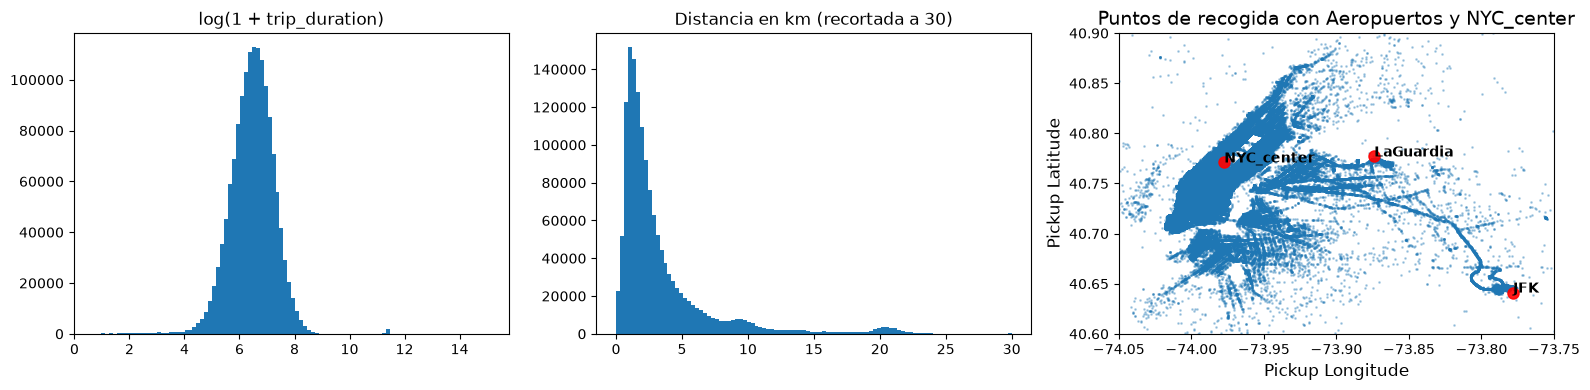

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(np.log1p(df["trip_duration"]), bins=100)
axes[0].set_title("log(1 + trip_duration)")

axes[1].hist(distancia_km.clip(upper=30), bins=100)
axes[1].set_title("Distancia en km (recortada a 30)")

# Grafica apra dibujar las dirrecciones de la conducción
#Definir las localizaciones de interés
JFK_location = [-73.778203, 40.641165]
LaGuardia_location = [-73.873923, 40.776935]
NYC_center = [-73.977282, 40.770940]

# Dibujar los puntos de recogida (scatter principal)
axes[2].scatter(df["pickup_longitude"], df["pickup_latitude"], s=1, alpha=0.3)

# Dibujar los puntos clave (Aeropuertos y Centro) sobre el mismo eje
axes[2].plot(JFK_location[0], JFK_location[1], 'o', color='r', alpha=0.9, markersize=8)
axes[2].plot(LaGuardia_location[0], LaGuardia_location[1], 'o', color='r', alpha=0.9, markersize=8)
axes[2].plot(NYC_center[0], NYC_center[1], 'o', color='r', alpha=0.9, markersize=8)

# Añadir los textos (anotaciones)
axes[2].annotate('NYC_center', (NYC_center[0], NYC_center[1]), color='black', fontsize=10, weight='bold')
axes[2].annotate('LaGuardia', (LaGuardia_location[0], LaGuardia_location[1]), color='black', fontsize=10, weight='bold')
axes[2].annotate('JFK', (JFK_location[0], JFK_location[1]), color='black', fontsize=10, weight='bold')

# Configurar límites, etiquetas y título
axes[2].set_xlim(-74.05, -73.75)
axes[2].set_ylim(40.6, 40.9)
axes[2].set_xlabel('Pickup Longitude', fontsize=12)
axes[2].set_ylabel('Pickup Latitude', fontsize=12)
axes[2].set_title('Puntos de recogida con Aeropuertos y NYC_center', fontsize=14)

plt.tight_layout()
plt.savefig("distribucion_atributos.png", dpi=150)
plt.show()

**Resultado:** `log(1 + trip_duration)` forma casi una campana centrada en ≈ 6,5 (≈ 660 s, la
mediana), con un pequeño pico aislado en ≈ 11,4, es decir ≈ 24 h (86.400 s), coherente con el
bloque de 23-24 h. La distancia se concentra en torno a 1 km, con cola larga y una pequeña
joroba hacia los 20 km. En el mapa se ve Manhattan y dos agrupaciones aisladas que, por sus
coordenadas, parecen ser JFK y LaGuardia (inferencia nuestra, sin comprobar).


### 7.1 Coordenadas y número de pasajeros

El eje de las coordenadas se limita al rectángulo de Nueva York **solo para dibujar**
(los puntos que quedan fuera ya se cuentan en 6.4). `passenger_count` es discreto
y tiene pocos valores, por eso va en barras.

**Suposición:** las coordenadas se concentrarán en un pico estrecho (Manhattan) y
`passenger_count` tendrá su pico en 1.


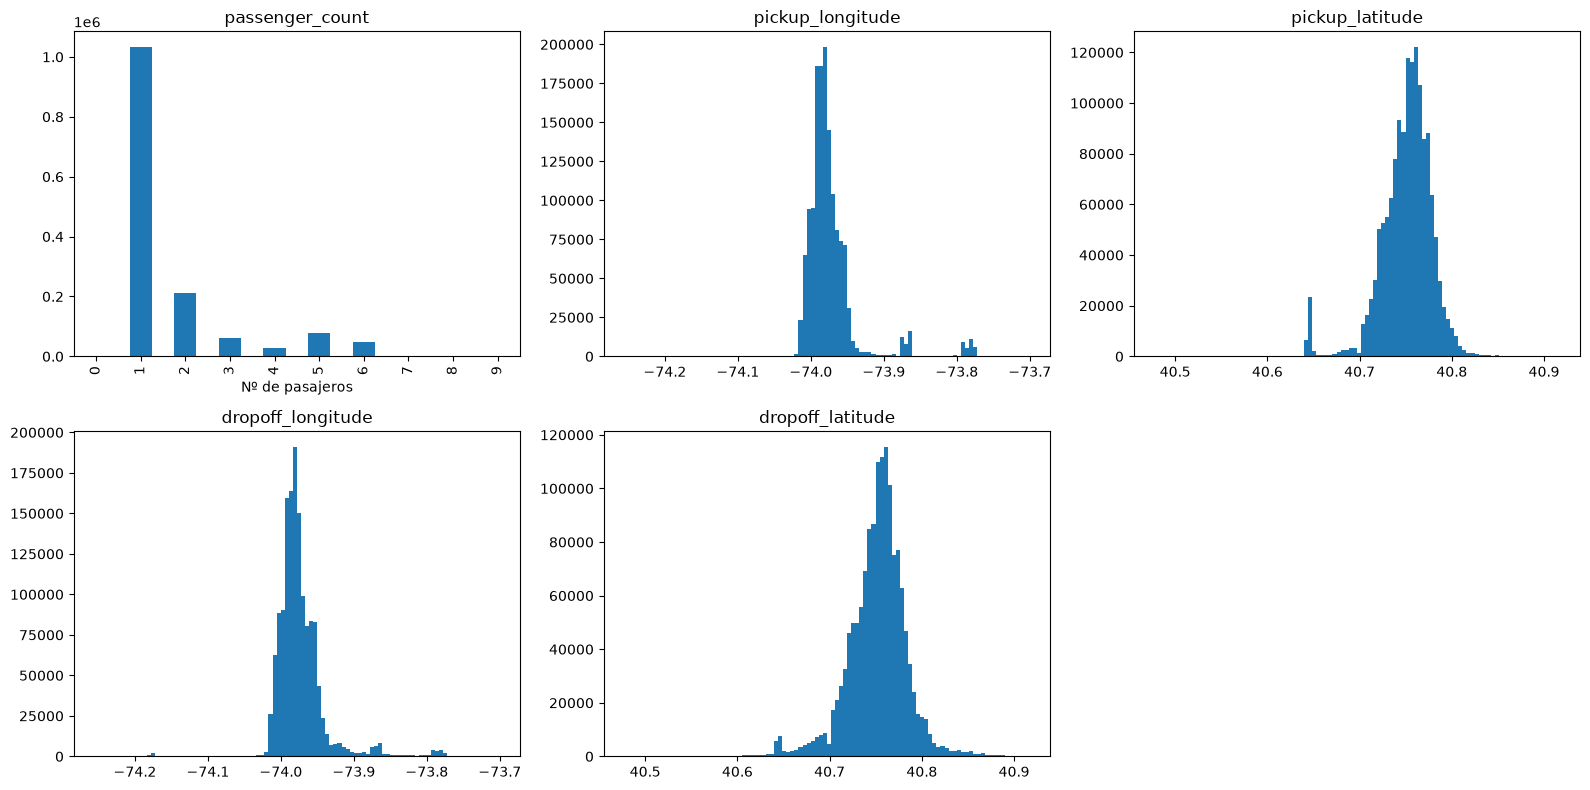

In [82]:

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

df["passenger_count"].value_counts().sort_index().plot.bar(ax=axes[0, 0])
axes[0, 0].set_title("passenger_count")
axes[0, 0].set_xlabel("Nº de pasajeros")

coords = [
    ("pickup_longitude",  axes[0, 1], (LON_MIN, LON_MAX)),
    ("pickup_latitude",   axes[0, 2], (LAT_MIN, LAT_MAX)),
    ("dropoff_longitude", axes[1, 0], (LON_MIN, LON_MAX)),
    ("dropoff_latitude",  axes[1, 1], (LAT_MIN, LAT_MAX)),
]
for col, ax, rango in coords:
    ax.hist(df[col], bins=100, range=rango)
    ax.set_title(col)

axes[1, 2].axis("off") 

plt.tight_layout()
plt.savefig("histogramas_coordenadas_pasajeros.png", dpi=150)
plt.show()

**Resultado:** las coordenadas se concentran en un pico estrecho y `passenger_count` tiene su pico en 1.

## 8. Correlación de los datos

- **Entre atributos (matriz de abajo):** pares con |correlación| alta son redundantes.
- **Atributo/clase (abajo):** como la clase es categórica, se compara cómo se reparte cada
   atributo dentro de cada clase. Si es parecido en las tres, el atributo aporta poco
   (posible irrelevancia).

Se usa Spearman en la matriz porque la duración tiene outliers muy extremos.

**Suposición:** `trip_duration` se correlaciona sobre todo con `distancia_km`, y las
coordenadas de recogida y de destino están correlacionadas entre sí (redundancia).


### 8.1 Correlación entre atributos

In [83]:
num = df[["passenger_count", "pickup_longitude", "pickup_latitude",
          "dropoff_longitude", "dropoff_latitude", "trip_duration"]].copy()
num["distancia_km"] = distancia_km
num["hora_recogida"] = df["pickup_datetime"].dt.hour
num["dia_semana"] = df["pickup_datetime"].dt.dayofweek

corr = num.corr(method="spearman").round(2)
corr

,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,distancia_km,hora_recogida,dia_semana
passenger_count,1.00,-0.01,-0.01,-0.01,-0.00,0.03,0.02,0.03,0.04
pickup_longitude,-0.01,1.00,0.59,0.40,0.31,0.03,0.07,-0.01,-0.04
pickup_latitude,-0.01,0.59,1.00,0.29,0.51,-0.11,-0.08,-0.00,-0.05
dropoff_longitude,-0.01,0.40,0.29,1.00,0.54,0.07,0.15,-0.03,-0.02
dropoff_latitude,-0.00,0.31,0.51,0.54,1.00,-0.12,-0.07,-0.00,-0.03
trip_duration,0.03,0.03,-0.11,0.07,-0.12,1.00,0.79,0.03,-0.03
distancia_km,0.02,0.07,-0.08,0.15,-0.07,0.79,1.00,0.01,0.03
hora_recogida,0.03,-0.01,-0.00,-0.03,-0.00,0.03,0.01,1.00,-0.06
dia_semana,0.04,-0.04,-0.05,-0.02,-0.03,-0.03,0.03,-0.06,1.00


**Resultado:**
- `trip_duration` se relaciona claramente solo con `distancia_km` (ρ = 0,79); con el resto, |ρ| ≤ 0,12.
- Entre coordenadas la redundancia es moderada: los pares más altos son pickup_lon–pickup_lat (0,59), dropoff_lon–dropoff_lat (0,54) y pickup_lat–dropoff_lat (0,51); ninguno llega a 0,8.
- `passenger_count`, `hora_recogida` y `dia_semana` no se relacionan con nada (|ρ| ≤ 0,06), pero Spearman solo detecta relaciones monótonas y la hora no tiene por qué serlo (horas punta), así que no basta para descartarla.


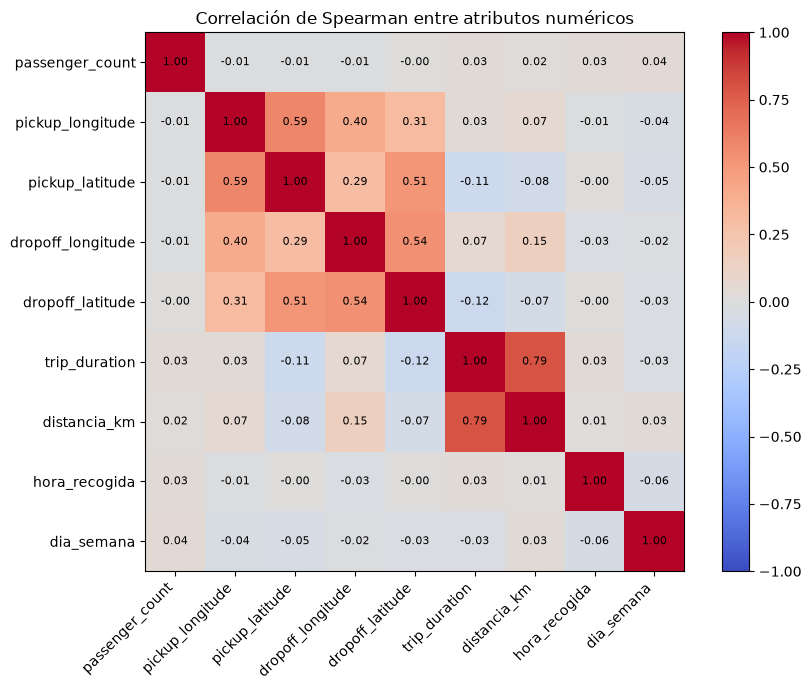

In [84]:
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

# Número dentro de cada casilla
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im)
ax.set_title("Correlación de Spearman entre atributos numéricos")
plt.tight_layout()
plt.savefig("matriz_correlacion.png", dpi=150)
plt.show()

### 8.2 Atributos numéricos frente a la clase
**Suposición:** la distancia cambiará mucho entre clases; `passenger_count` y
`dia_semana`, casi nada.

In [85]:
num["clase"] = columna_clase_transformada

# Mediana por clase (mejor que la media por los outliers)
num.groupby("clase")[["distancia_km", "passenger_count", "hora_recogida", "dia_semana"]] \
   .median().reindex(orden).round(2)

,distancia_km,passenger_count,hora_recogida,dia_semana
clase,,,,
short,1.25,1.0,14.0,3.0
medium,2.93,1.0,14.0,3.0
long,8.74,1.0,14.0,3.0


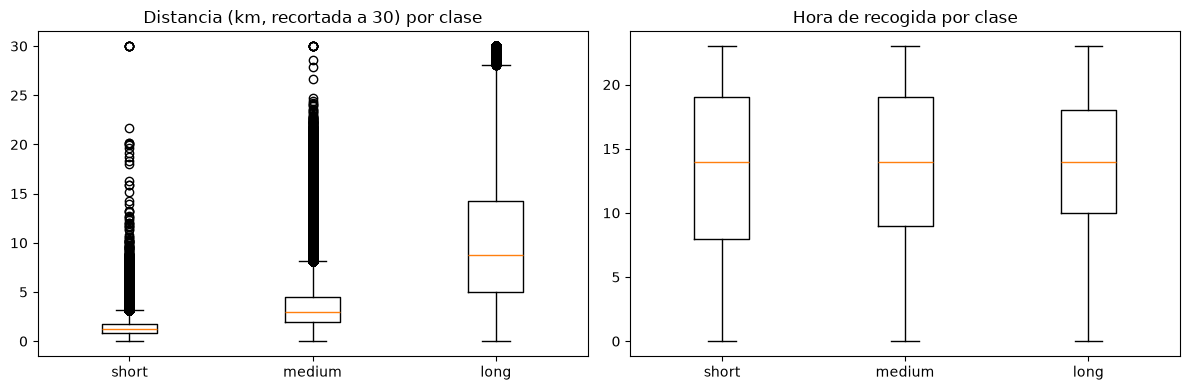

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

datos = [distancia_km[num["clase"] == c].clip(upper=30) for c in orden]
axes[0].boxplot(datos, tick_labels=orden)
axes[0].set_title("Distancia (km, recortada a 30) por clase")

datos = [num.loc[num["clase"] == c, "hora_recogida"] for c in orden]
axes[1].boxplot(datos, tick_labels=orden)
axes[1].set_title("Hora de recogida por clase")

plt.tight_layout()
plt.savefig("atributos_por_clase.png", dpi=150)
plt.show()

**Resultado:**
- **Distancia:** es el atributo que mejor separa las clases. La mediana crece con la clase: 1,25 km (short), 2,93 (medium) y 8,74 (long).
- **`passenger_count` y `dia_semana`:** misma mediana en las tres clases (1 y 3). La mediana no basta para descartarlos; se estudian en 8.3 y 8.4.
- **`hora_recogida`:** misma mediana (14) en las tres clases. Se estudia en 8.4.
- En `short` hay viajes de más de 20 km; en ≤ 10 min serían > 120 km/h, es decir, ruido, pero por la razón de 6.5 no se usa la velocidad para limpiar.

### 8.3 Atributos categóricos frente a la clase

Para cada valor del atributo, qué % de sus viajes es short, medium y long. Cada fila suma
100 %. Si el reparto es casi igual en todas las filas, el atributo no aporta.


In [87]:
df_clase = pd.Series(columna_clase_transformada, name="clase")

for col in ["vendor_id", "store_and_fwd_flag", "passenger_count"]:
    print(f"\n--- {col} (% de cada clase dentro de cada valor) ---")
    print((pd.crosstab(df[col], df_clase, normalize="index") * 100)
        .reindex(columns=orden).round(1))



--- vendor_id (% de cada clase dentro de cada valor) ---
clase      short  medium  long
vendor_id                     
1           45.1    42.9  12.0
2           44.5    42.8  12.7

--- store_and_fwd_flag (% de cada clase dentro de cada valor) ---
clase               short  medium  long
store_and_fwd_flag                     
N                    44.8    42.9  12.3
Y                    36.7    41.0  22.3

--- passenger_count (% de cada clase dentro de cada valor) ---
clase            short  medium  long
passenger_count                     
0                 83.3     6.7  10.0
1                 45.4    42.6  12.0
2                 42.7    43.6  13.7
3                 42.7    43.9  13.4
4                 41.9    44.0  14.1
5                 44.2    43.1  12.7
6                 44.7    42.9  12.4
7                100.0     0.0   0.0
8                100.0     0.0   0.0
9                100.0     0.0   0.0


**Resultado:**
- `vendor_id`: reparto casi igual al global (diferencias ≤ 0,7 puntos); aporta poco.
- `store_and_fwd_flag`: con Y hay más long (22,3 % frente a 12,3 % con N), pero Y es solo el 0,55 % de los viajes.
- `passenger_count`: de 1 a 6, long varía entre 12,0 y 14,1 %: relación débil. Con 0 pasajeros (60 viajes) el 83,3 % es short y con 7-9 (5 viajes) el 100 %, pero son muy pocos casos.


### 8.4 Atributos temporales frente a la clase

Las medianas de la sección 8.2 y la correlación de Spearman de la sección 8 no distinguen la hora ni el día de la semana, pero ambas solo detectan relaciones monótonas y estas variables no lo son (la hora punta no crece ni decrece de forma lineal). Por eso se mira, como en 8.3, qué % de cada clase hay dentro de cada valor de `hora`, `día de la semana` y `mes`, extraídos de `pickup_datetime`. Si el reparto cambia entre valores, el atributo aporta información.

**Suposición:** la hora varía más que el día y el mes, porque el tráfico cambia a lo largo del día.

In [88]:
df_clase = pd.Series(columna_clase_transformada, name="clase")

for nombre, serie in [("hora", df["pickup_datetime"].dt.hour),
                      ("día de la semana", df["pickup_datetime"].dt.dayofweek),
                      ("mes", df["pickup_datetime"].dt.month)]:
    print(f"\n--- {nombre} (% de cada clase) ---")
    print((pd.crosstab(serie, df_clase, normalize="index") * 100)
          .reindex(columns=orden).round(1))


--- hora (% de cada clase) ---
clase            short  medium  long
pickup_datetime                     
0                 46.1    43.4  10.5
1                 48.8    42.8   8.4
2                 51.0    42.3   6.8
3                 50.7    42.4   6.9
4                 49.3    41.9   8.9
5                 56.2    33.0  10.8
6                 62.4    29.1   8.5
7                 52.5    38.4   9.1
8                 44.9    43.2  12.0
9                 43.4    43.9  12.7
10                43.6    43.2  13.2
11                41.8    44.1  14.2
12                41.4    44.4  14.3
13                41.2    44.0  14.8
14                40.0    43.5  16.5
15                40.7    42.3  17.1
16                42.7    40.2  17.1
17                42.1    41.9  15.9
18                42.7    44.3  13.0
19                45.6    44.3  10.1
20                46.8    43.9   9.3
21                46.2    44.2   9.7
22                44.1    45.0  10.9
23                44.0    44.4  11.6

--- d

**Resultado:**
- **Hora:** es la variable con más señal. El % de `long` pasa de ≈ 6,8 % (2-3 h) a ≈ 17 % (15-16 h), más del doble, y la forma no es monótona: sube de madrugada a la tarde y baja por la noche. Por eso Spearman no la detectaba. A las 5-6 h destaca `short` (56-62 %) y baja `medium` (29-33 %).
- **Día de la semana** (0 = lunes, 6 = domingo): `long` ≈ 11,5-14,7 % de lunes a jueves y ≈ 9,9 % en sábado y domingo. Se aprecia el contraste entre días laborables y fin de semana, pero es un efecto moderado.
- **Mes:** `long` crece casi cada mes, de 10,6 % (enero) a 14,5 % (junio). Hay tendencia, pero el dataset solo cubre seis meses y no se puede asumir que se mantenga en otras épocas del año.
- Estos resultados sustituyen la lectura anterior del boxplot de la hora, que era un indicio mucho más débil.

**Decisión:** se mantienen `hora` y `día de la semana`. El `mes` se descarta por no generalizar.

## 9. Observaciones para la limpieza

Aquí no se modifica nada: es la lista de operaciones de la etapa siguiente, con el motivo de cada decisión.

**Sin problemas detectados:** 0 ausentes, 0 duplicados, 0 duraciones <= 0 s.

### 9.1 Filas a eliminar

Las cifras son individuales (6.6) y se solapan, por lo que no se suman. En test, las filas eliminadas se cuentan como NTAIE (inconsistentes) o NTOE (outliers), con prioridad para NTAIE.

| Criterio | Filas | Tipo | Motivo |
|---|---|---|---|
| `passenger_count` = 0 o > 6 | 65 | NTAIE | Valores no válidos para un taxi |
| Recogida o destino fuera del rectángulo amplio (lat 40,0–41,5; lon −74,8 a −73,0) | 81 (35 recogidas y 46 destinos) | NTAIE | Imposibles para un taxi de NYC. Se aplica el mismo criterio a ambos puntos. Los límites son una elección propia |
| 0 km y duración > 5 min | 3.191 | NTAIE | Contradice la variable más predictiva (la distancia) |
| Duración < 60 s | 8.595 | NTOE | Un viaje real de menos de 1 min es implausible |
| Duración > 3 h | 2.112 | NTOE | 1.843 superan las 23 h: artefacto (por ejemplo, taxímetro sin apagar) |

**Filtro combinado:** 13.945 filas (0,956 %). El balance de clases pasa de 44,76 / 42,87 / 12,37 % a 44,51 / 43,17 / 12,32 % (short / medium / long).

### 9.2 Lo que se mantiene

- Coordenadas fuera del rectángulo ajustado de NYC pero dentro del amplio (305 recogidas y 1.329 destinos): pueden ser viajes reales (901 de los destinos son `long`).
- 0 km con duración ≤ 5 min (≈ 2.700): coherentes con la clase `short`.
- Velocidad > 100 km/h (175): no se usa como criterio porque se calcula con `trip_duration`.

### 9.3 Atributos

| Atributo | Decisión | Motivo |
|---|---|---|
| `id` | Eliminar | Identificador único, sin valor predictivo |
| `dropoff_datetime` | Eliminar | Fuga de información (0 discrepancias con `dropoff - pickup`: revela la duración) y no se conoce al empezar el viaje |
| `vendor_id` | Eliminar | Reparto de clases casi igual al global (diferencias ≤ 0,7 puntos) |
| `trip_duration` | Eliminar | Solo sirve para construir la clase |
| `pickup_datetime` | Eliminar | Se sustituye por hora y día extraídos |
| `distancia_km` | Construir | ρ = 0,79 con la duración; medianas 1,25 / 2,93 / 8,74 km por clase |
| `hora_recogida` | Construir | `long` pasa de ≈ 6,8 % (2-3 h) a ≈ 17 % (15-16 h) |
| `dia_semana` | Construir | `long` ≈ 11,5-14,7 % entre semana y ≈ 9,9 % en fin de semana |
| `mes` | Descartar | Solo cubre 6 meses: la tendencia no generaliza |
| `passenger_count` | Mantener | Relación débil (long 12,0-14,1 %), se conserva como candidato |
| `store_and_fwd_flag` | Mantener | long 22,3 % con Y frente a 12,3 % con N, aunque solo afecta al 0,55 % de las filas |
| Coordenadas | Mantener | Spearman solo detecta relaciones monótonas (máximo 0,59 entre ellas, sin redundancia fuerte), así que no permite descartarlas |

En Scala los atributos construidos se llaman `distance_km`, `pickup_hour` y `pickup_day`. `pickup_day` usa `dayofweek` de Spark (1 = domingo … 7 = sábado), distinto de la exploración (0 = lunes … 6 = domingo); el cambio de numeración no afecta al modelo.

### 9.4 Posible desbalanceo

`long` es el 12,37 %, `short` el 44,76 % y `medium` el 42,87 %. Predecir siempre `short` acertaría un 44,76 %: es el listón mínimo de la exactitud. Como `long` es una minoría clara, además de la exactitud conviene evaluar con una métrica por clase, la **F1 macro**.

Con este volumen de datos, una partición aleatoria con semilla conserva el reparto, así que no hace falta estratificar. Resultado en Scala (`randomSplit` 80/20, `seed = 42`):

| Conjunto | Instancias | short (%) | medium (%) | long (%) |
|---|---|---|---|---|
| Original | 1.458.644 | 44,76 | 42,87 | 12,37 |
| Entrenamiento | 1.166.855 | 44,79 | 42,84 | 12,37 |
| Prueba | 291.789 | 44,63 | 42,98 | 12,38 |

### 9.5 Suposiciones y limitaciones

- La limpieza se aplica a train y a test con las mismas reglas. En test se cuentan las filas eliminadas (NTAIE y NTOE) y se informa de la tasa de no clasificados, que debe ser al menos un orden de magnitud menor que la tasa de error. Como se filtra por duración (la etiqueta), la tasa de error se mide sobre datos limpios y no refleja el caso real.
- Las coordenadas de destino solo se conocen al final del viaje. Usar `distancia_km` supone que el destino se declara al inicio.
- El mes cubre solo seis meses, y los resultados no se extrapolan a otras épocas del año.
- Resultado de la limpieza en Scala: entrenamiento 1.166.855 → 1.155.830 (11.025 eliminadas, 0,945 %); prueba 291.789 → 288.869 (2.920 eliminadas, 1,00 %).
- En prueba: NTAIE = 663 y NTOE = 2.257. Tasa de no clasificados = 2.920 / 291.789 ≈ 1,00 %, por lo que la tasa de error del clasificador deberá ser ≥ 10 % para cumplir el requisito.
